In [1]:
%matplotlib inline
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import gc
import torch.nn.functional as F
from torch.utils.data import random_split
import matplotlib.pyplot as plt
import numpy as np
import math

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')


import sys 
sys.path.insert(0,'../modules')
sys.path.append('../third_party/image_manipulation_code')
torch.manual_seed(42) 

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from KLD_loss import loss_function

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import gc
import torch.nn.functional as F
from torch.optim.lr_scheduler import StepLR
from torch.utils.data import Dataset, DataLoader, random_split

import sys 

In [2]:
import argparse
import os
from argparse import BooleanOptionalAction

import numpy as np
import torch
from PIL import Image
from diffusers import DDIMScheduler, StableDiffusionImg2ImgPipeline

from nsd_datasets.nsd import NaturalScenesDataset
from nsd_datasets.nsd_clip import CLIPExtractor, NSDCLIPFeaturesDataset
from IPA.ip_adapter import IPAdapter
from methods.slerp import slerp
from methods.projection import project_modulation_vector
from methods.dino_encoder import EncoderModule
from methods.CLIP_VAE import CLIPtoCLIPVAE  # CLIP-to-CLIP VAE model

from torchvision import transforms

### Load Full NSD Dataset

In [3]:
# Load Full NSD dataset with selected Regions of Interest, Activations are averaged via voxels.


nsd_transform = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.ToTensor()
])

subj1_lh_rois = ["aTL-faces", "EBA", "FBA-1", "FFA-1", "mfs-words",
                 "OFA", "OPA", "OWFA"]
sub_1_lh_rois_unknown = ["IPS4", "SPL1", "TO1", "PHC2", "VO2", "PGi", "VVC", "TE2a"]
sub_1_lh_rois_explored = ["OFA", "FFA-1", "EBA", "VWFA-1", "OPA", "PPA", "RSC", "OWFA"]
sub_1_lh_rois_unknown_ex = ["STSdp", "31a", "31pd", "DVT", "FST", "PGp", "PGs", "PH"]


trainset=NaturalScenesDataset(
                    root="../datasets/NSD_ex_1",
                    subject=1,
                    partition='train',
                    hemisphere='lh',
                    transform = nsd_transform,
                    roi=sub_1_lh_rois_unknown_ex,
                    return_average=True,
                    tval_threshold=5
)

testset = NaturalScenesDataset(
                    root="../datasets/NSD_ex_1",
                    subject=1,
                    partition='test',
                    hemisphere='lh',
                    transform = nsd_transform,
                    roi=sub_1_lh_rois_unknown_ex,
                    return_average=True,
                    tval_threshold=5
)

[INFO] No tval file found for ROI 'STSdp' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI '31a' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI '31pd' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI 'DVT' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI 'FST' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI 'PGp' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI 'PGs' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI 'PH' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI 'STSdp' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI '31a' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI '31pd' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI 'DVT' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI 'FST' in lh, skipping tval thresholding.
[INFO] No tval file 

In [4]:
# Load CLIP Features
nsd_CLIP = NSDCLIPFeaturesDataset(
                            nsd=NaturalScenesDataset(
                                root="../datasets/NSD_ex_1",
                                subject=1,
                                partition='all',
                                hemisphere='lh',
                                transform = nsd_transform,
                                roi=sub_1_lh_rois_unknown_ex,
                                return_average=True,
                                tval_threshold=5
            )
        )

[INFO] No tval file found for ROI 'STSdp' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI '31a' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI '31pd' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI 'DVT' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI 'FST' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI 'PGp' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI 'PGs' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI 'PH' in lh, skipping tval thresholding.


In [5]:
trainloader = DataLoader(trainset, batch_size=100, shuffle=False, num_workers=2)
testloader = DataLoader(testset, batch_size=100, shuffle=False, num_workers=2)
cliploader = DataLoader(nsd_CLIP, batch_size=100, shuffle=False, num_workers=2)

### Visualize CLIP space vs organized VAE latent space

In [3]:
# Load trained VAE
z_dim = 2048
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
CLIP_Transform_Encoder = CLIPtoCLIPVAE(latent_dim=z_dim, input_dim=1024).to(device)

state_dict = torch.load(
    '../checkpoints/LW_CLIPtoCLIP_VAE_NSD_31pd_Constrain_zdim_2048_KLD_01_lamb_01.pt',
    map_location=device
)

# Load the state dict into your model
CLIP_Transform_Encoder.load_state_dict(state_dict)

<All keys matched successfully>

In [7]:
# Load CLIP Features
CLIP_features = []
images = []
for i in range (len(nsd_CLIP)):
    images.append(nsd_CLIP[i][0])
    CLIP_features.append(nsd_CLIP[i][1])
CLIP_features = np.array(CLIP_features)
CLIP_features = torch.from_numpy(CLIP_features)

In [9]:
# Encode the CLIP Features into organized space via trained VAE
with torch.no_grad():
    CLIP_Transform_Encoder.eval()
    CLIP_Recon = CLIP_Transform_Encoder(CLIP_features.to(device))[0]
    mu, logvar = CLIP_Transform_Encoder.encode(CLIP_features.to(device)) 

In [17]:
# Define Visualization Function

def to_np(tensor_input):
    return tensor_input.detach().cpu().numpy()
from scipy.interpolate import griddata

def visualize_loss_landscape_unit(unit_idx, principal_components, loader):
    losses = []
    with torch.no_grad():
        for (_, _, loss) in loader:
            #data = data.to(device)
            losses.append(loss[:, unit_idx])
    
    losses_vis = torch.concat(losses)
    sort_indexes = np.argsort(to_np(losses_vis))

    # Sample data:
    x = to_np(principal_components[:, 0])
    y = to_np(principal_components[:, 1])
    z = to_np(losses_vis)
    


    # Create a grid in the range (-2, 2)
    xi = np.linspace(-2, 2, 100)
    yi = np.linspace(-2, 2, 100)
    Xi, Yi = np.meshgrid(xi, yi)

    # Interpolate z values onto this grid
    Zi = griddata((x, y), z, (Xi, Yi), method='linear')

    # 3D surface plot
    fig = plt.figure(figsize=(15, 12))
    ax = fig.add_subplot(111, projection='3d')
    surf = ax.plot_surface(Xi, Yi, Zi, cmap='jet')
    cbar = fig.colorbar(surf)
    cbar.ax.set_yticklabels([])
    #ax.set_xlabel('test MouseNet Latent 1')
    #ax.set_ylabel('test MouseNet Latent 2')
    #ax.set_zlabel('unit activation loss')
    #ax.set_title('unit activation loss over test images')
    ax.set_xlim(-2, 2)
    ax.set_ylim(-2, 2)
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_zticklabels([])
    #cbar = fig.colorbar(surf)
    ax.scatter(x, y, z, color='black', s=0.01)
    ax.view_init(elev=37, azim=270)
    plt.show()

    # 2D contour plot
    plt.figure(figsize=(8, 6))
    cp = plt.contourf(Xi, Yi, Zi, cmap='jet', levels=50)
    plt.colorbar(cp)
    plt.xlabel('dim 0')
    plt.ylabel('dim 1')
    plt.xlim(-2, 2)
    plt.ylim(-2, 2)
    plt.title('Activation over images')
    plt.scatter(x, y, color='black', s=0.05)
    plt.show()

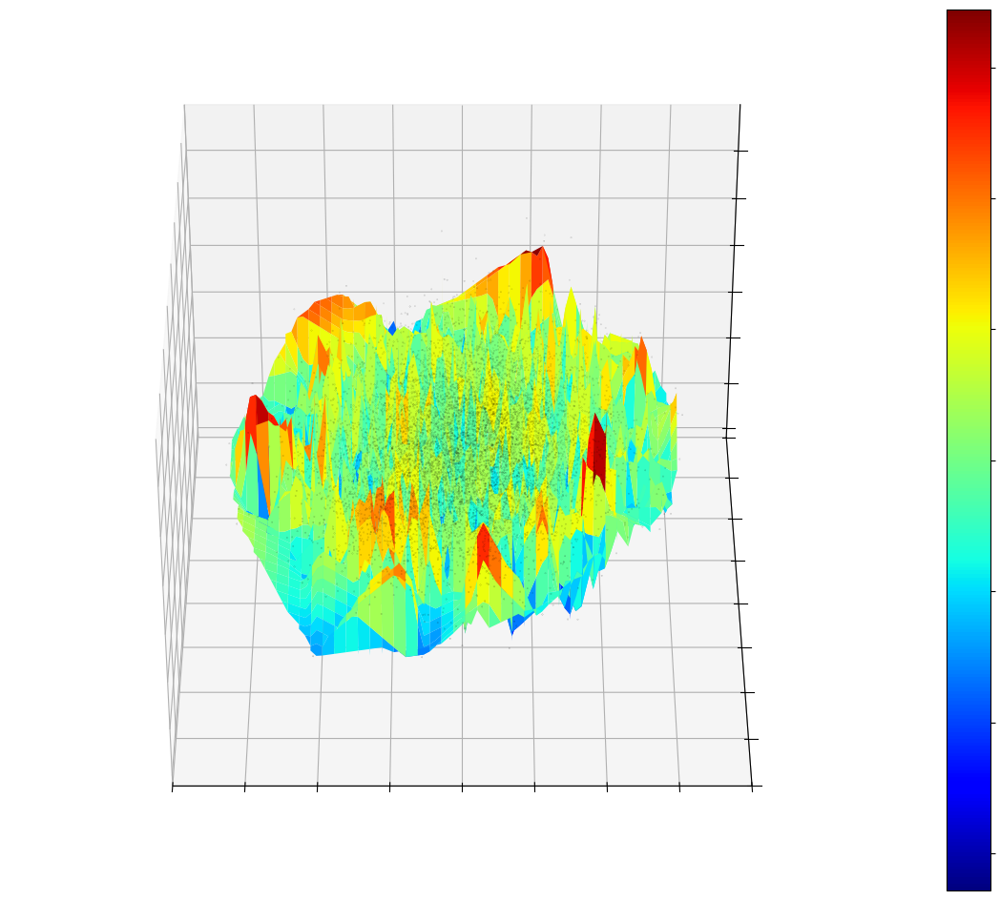

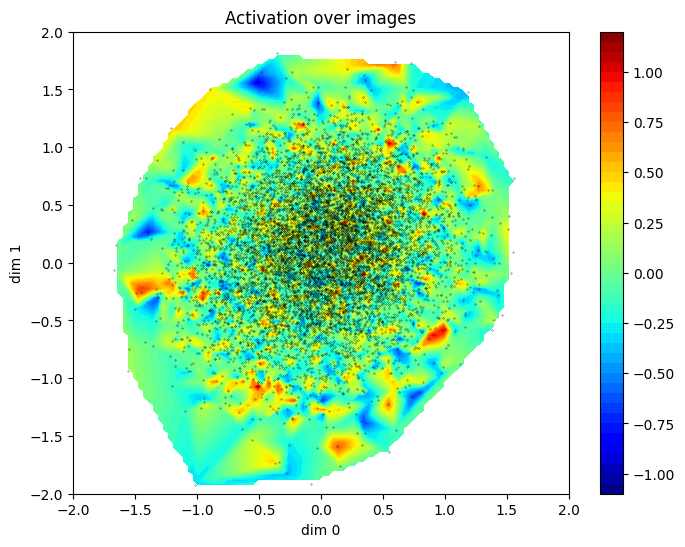

In [18]:
# Original CLIP Features
# Note: The unit_idx here should match the index of the ROI in the list of ROIs passed to "roi" parameter when init the nsd dataset
unit_idx = 2
visualize_loss_landscape_unit(unit_idx = unit_idx,
                              principal_components = CLIP_features[:,[0,1]],
                             loader = cliploader)

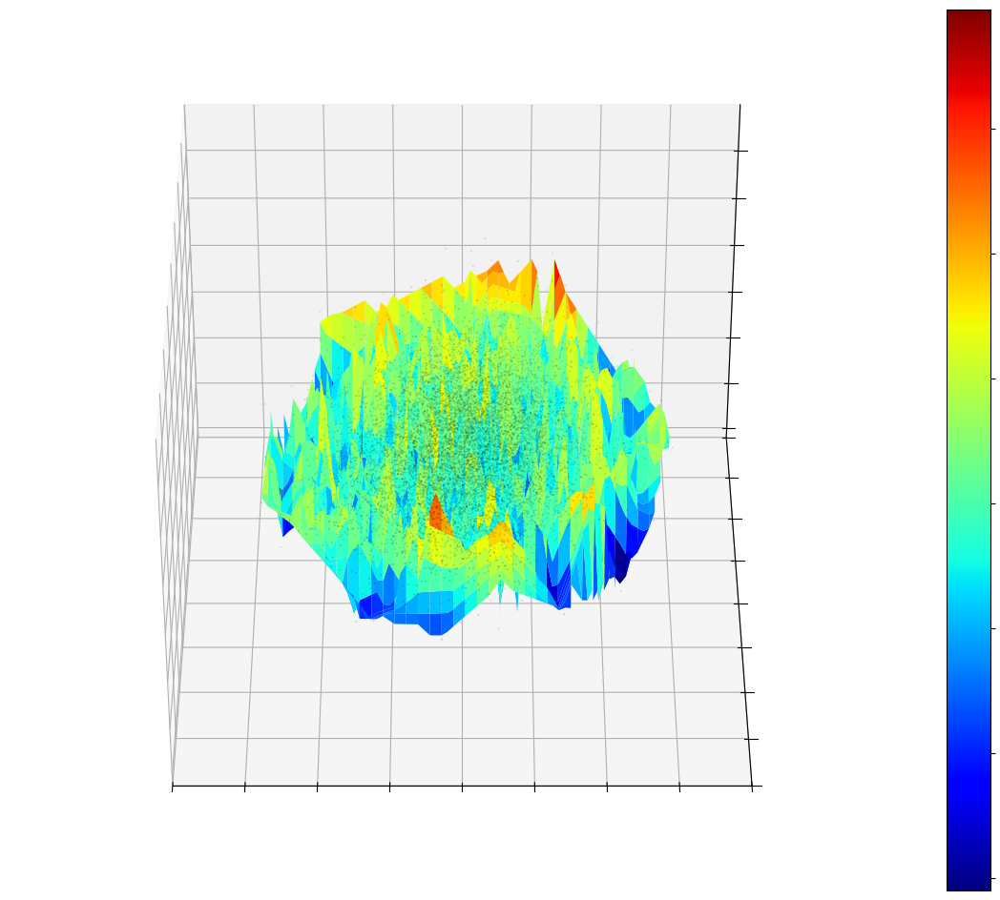

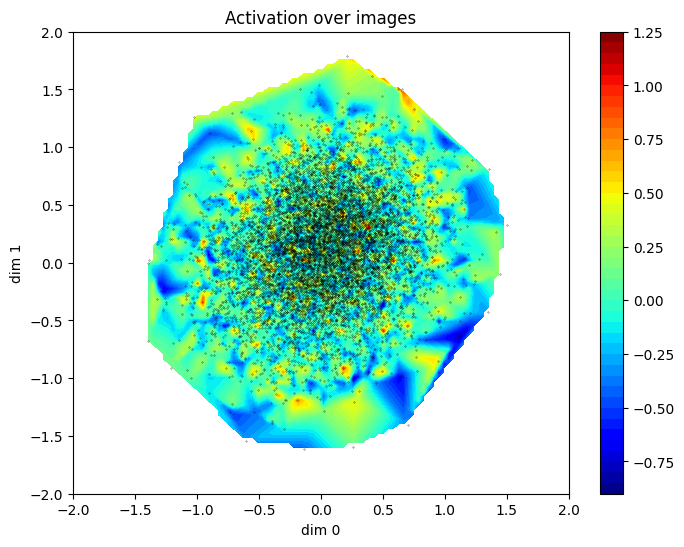

In [19]:
# Reconstructed CLIP Features by VAE

unit_idx = 2
visualize_loss_landscape_unit(unit_idx = unit_idx,
                              principal_components = CLIP_Recon[:,[0,1]],
                              loader = cliploader)

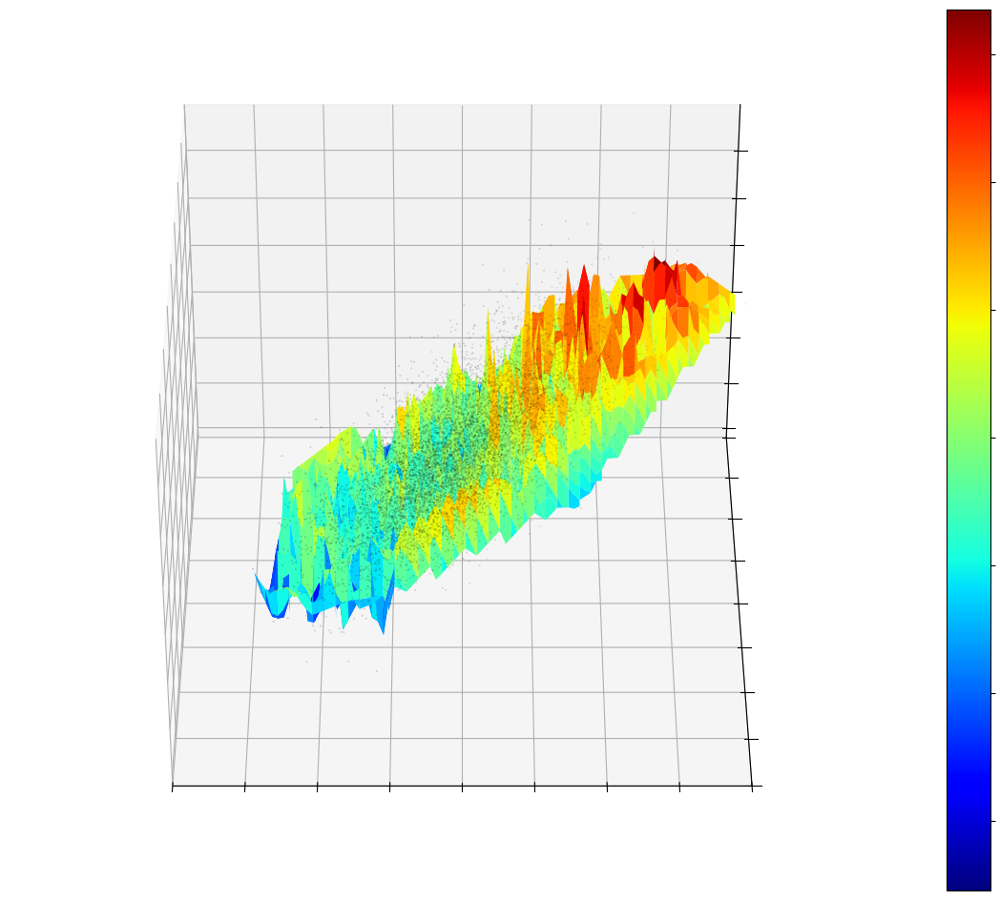

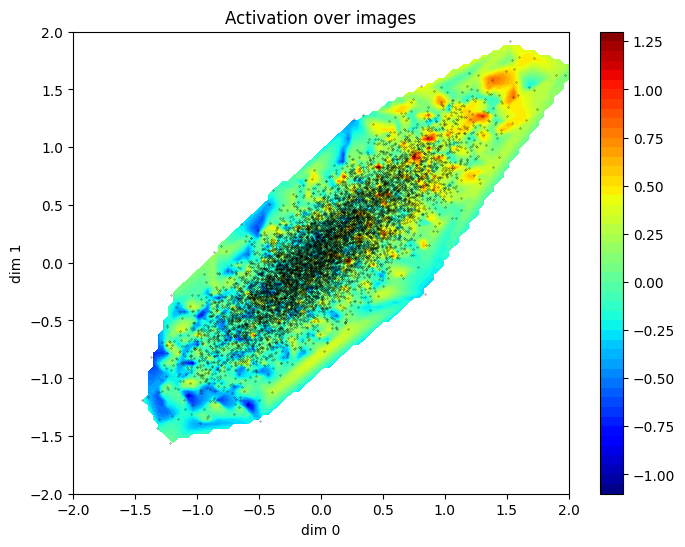

In [20]:
# Origanized Latent Space
unit_idx = 2
visualize_loss_landscape_unit(unit_idx = unit_idx,
                              principal_components = mu[:,[0, 1]],
                             loader = cliploader)

### Visualize the generated preferred images of Our Method vs Baseline

In [4]:
# Load diffsuion Pipeline
diffusion_pipeline = StableDiffusionImg2ImgPipeline.from_pretrained("runwayml/stable-diffusion-v1-5", torch_dtype=torch.float16).to(device)
diffusion_pipeline.scheduler = DDIMScheduler.from_config(diffusion_pipeline.scheduler.config)
diffusion_pipeline.safety_checker = None
ip_model = IPAdapter(diffusion_pipeline, "laion/CLIP-ViT-H-14-laion2B-s32B-b79K", os.path.join("../third_party/image_manipulation_code/models", "ip-adapter_sd15.bin"), device)

Cannot initialize model with low cpu memory usage because `accelerate` was not found in the environment. Defaulting to `low_cpu_mem_usage=False`. It is strongly recommended to install `accelerate` for faster and less memory-intense model loading. You can do so with: 
```
pip install accelerate
```
.


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

In [5]:
sub_1_lh_rois_unknown = ["IPS4", "SPL1", "TO1", "PHC2", "VO2", "PGi", "VVC", "TE2a"]
sub_1_lh_rois = ["aTL-faces", "EBA", "FBA-1", "FFA-1", "mfs-words",
                 "OFA", "OPA", "OWFA"]
sub_1_lh_rois_explored = ["OFA", "FFA-1", "EBA", "VWFA-1", "OPA", "PPA", "RSC", "OWFA"]
sub_1_lh_rois_unknown_ex = ["STSdp", "31a", "31pd", "DVT", "FST", "PGp", "PGs", "PH"]
sub_1_lh_rois_unknown_ex_2 = ["TE2p", "PHT", "TPOJ1", "TPOJ2", "TPOJ3", "IP0", "IP1", "IP2"]
sub_1_lh_rois_mix = ["V1", "V2", "V3", "V4", "V8", "LO1", "LO2", "V4t"]

Using cache found in /common/home/yz1635/.cache/torch/hub/facebookresearch_dinov2_main


  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

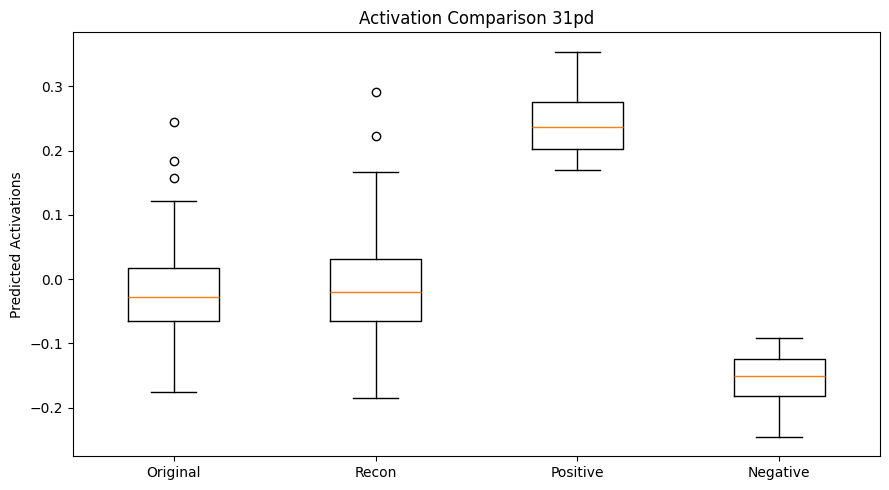

In [6]:
#### Generate preferred images with our method, test images are selected by baseline methods
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from methods.dino_encoder import EncoderModule
from nsd_datasets.nsd_clip import CLIPExtractor

# === CONFIG ===
unit_idx = 2
ROI = sub_1_lh_rois_unknown_ex[unit_idx]
resize_to = 224
alpha = 1.0
gamma = 1.0

# === PATHS ===
img_dir = "../third_party/image_manipulation_code/outputs/1_" + ROI + "_" + str(alpha) + "_" + str(gamma) +  "/img"
ckpt_path_dino = "../checkpoints/dino_encoder-lh-unknown-8-ROI-ex-epoch=02-val_loss=0.11.ckpt"

# === MODELS ===
encoder_dino = EncoderModule.load_from_checkpoint(ckpt_path_dino, strict=False).eval().to(device)
clip_extractor = CLIPExtractor(device=device)


# === IMAGE PREP ===
transform_dino = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def load_images(directory):
    paths = sorted([os.path.join(directory, f) for f in os.listdir(directory) if f.endswith('.png')],
                   key=lambda x: int(os.path.splitext(os.path.basename(x))[0]))
    return [Image.open(p).convert("RGB") for p in paths]

images_batch = load_images(img_dir)

# === STEP 1: Extract CLIP features for originals ===
with torch.no_grad():
    clip_feats = torch.stack([clip_extractor(img) for img in images_batch]).to(device)

# === STEP 2: Encode to latent ===
mu, logvar = CLIP_Transform_Encoder.encode(clip_feats)
# === STEP 3: Latent Edit ===
mu_pos = mu.clone()
mu_neg = mu.clone()
#Multiple ROI Constrain
"""
for unit in clip_unit_idxs:
    for d in range(latent_dim):
        mu_pos[idx, d * channels_per_block + unit] = 1.0
        mu_neg[idx, d * channels_per_block + unit] = -1.0
"""
#Single ROI Constrain
mu_target_pos = torch.ones_like(mu)
mu_target_neg = -torch.ones_like(mu)

mu_pos = (1-alpha) * mu + alpha * mu_target_pos
mu_neg = (1-alpha) * mu + alpha * mu_target_neg


z_pos = CLIP_Transform_Encoder.reparameterize(mu_pos, logvar)
z_neg = CLIP_Transform_Encoder.reparameterize(mu_neg, logvar)

clip_recon = CLIP_Transform_Encoder.decode(mu)
clip_pos = CLIP_Transform_Encoder.decode(mu_pos)
clip_neg = CLIP_Transform_Encoder.decode(mu_neg)

# === STEP 4: Run Diffusion ===
recons = ip_model.generate(
    clip_image_embeds=clip_recon,
    image=images_batch,
    strength=gamma,
    num_samples=1,
    num_inference_steps=50,
    seed=42
)

edited_pos = ip_model.generate(
    clip_image_embeds=clip_pos,
    image=images_batch,
    strength=gamma,
    num_samples=1,
    num_inference_steps=50,
    seed=42
)

edited_neg = ip_model.generate(
    clip_image_embeds=clip_neg,
    image=images_batch,
    strength=gamma,
    num_samples=1,
    num_inference_steps=50,
    seed=42
)

# === STEP 5: DINO Activation ===
def extract_dino(images):
    feats = []
    with torch.no_grad():
        for img in images:
            tensor = transform_dino(img).unsqueeze(0).to(device)
            feat = encoder_dino(tensor)[0, unit_idx].cpu().item()
            feats.append(feat)
    return np.array(feats)

act_original = extract_dino(images_batch)
act_recon = extract_dino(recons)
act_pos = extract_dino(edited_pos)
act_neg = extract_dino(edited_neg)

# === STEP 6: Plot Final Boxplot ===
plt.figure(figsize=(9, 5))
plt.boxplot([act_original, act_recon, act_pos, act_neg],
            labels=['Original', 'Recon', 'Positive', 'Negative'],
            showfliers=True)
plt.ylabel(f"Predicted Activations")
plt.title(f"Activation Comparison {ROI}")
plt.tight_layout()
plt.show()

Original


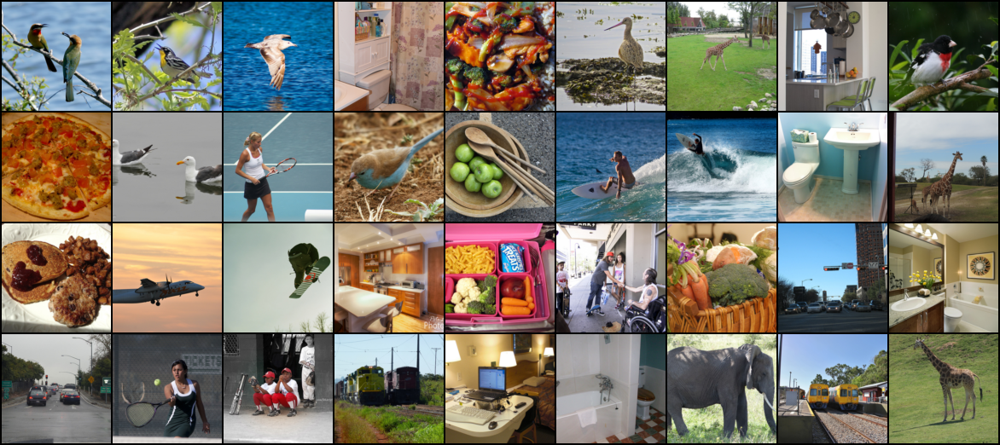

Reconstructed


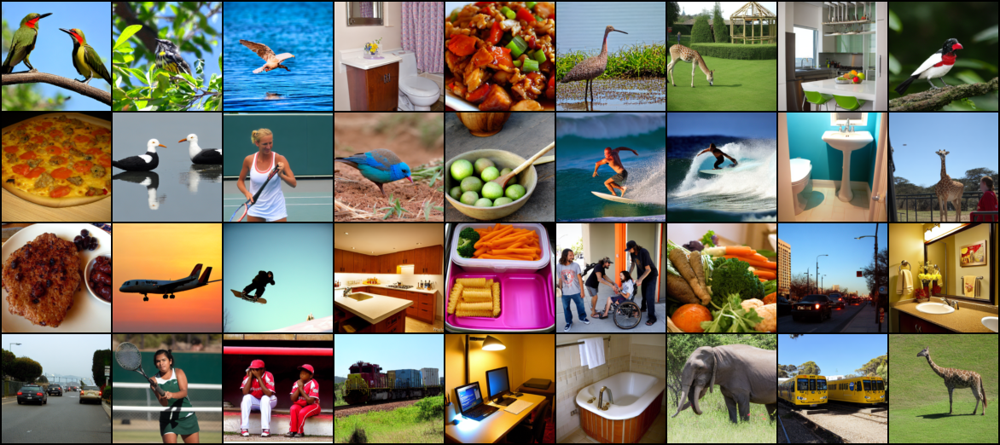

Edited (+1)


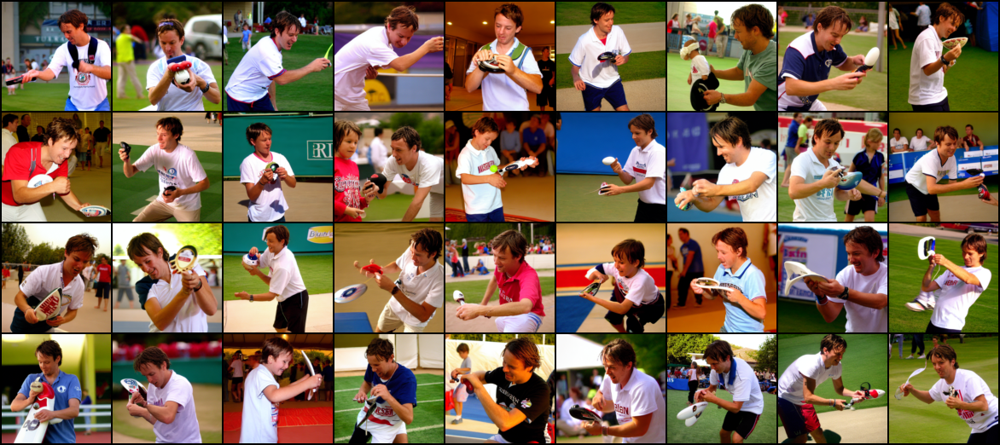

Edited (-1)


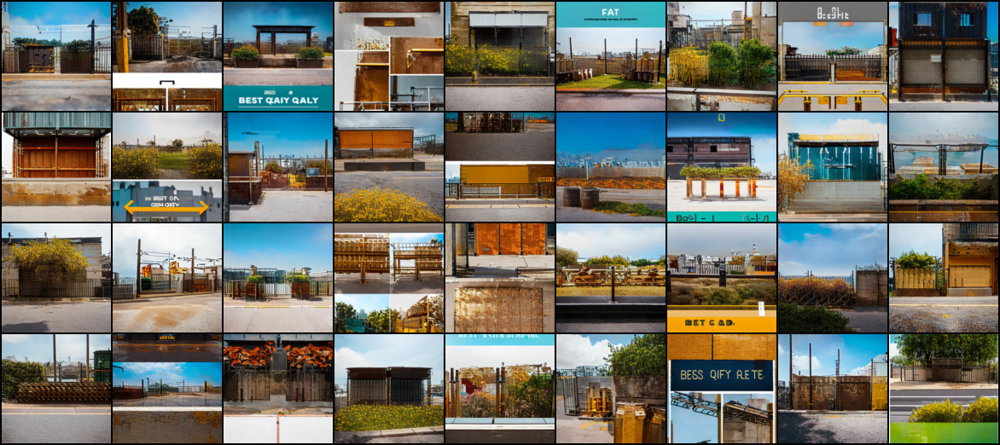

In [7]:
#Display the results of our method
import torchvision.transforms as T
from IPython.display import display
from torchvision.utils import make_grid
resize_to = 128

def build_grid(image_list, resize_to=128, images_per_row=9):
    # Normalize + Resize
    transform = T.Compose([
        T.Resize((resize_to, resize_to)),
        T.ToTensor()
    ])
    
    # Apply transform & collect tensors
    tensors = [transform(img) for img in image_list[:36]]  # each is [3, H, W]
    batch_tensor = torch.stack(tensors)  # shape: [B, 3, H, W]

    # Use torchvision's make_grid to avoid shape issues
    grid = make_grid(batch_tensor, nrow=images_per_row, padding=2)
    return T.ToPILImage()(grid.clamp(0, 1))
   
print("Original")
display(build_grid(images_batch, resize_to=128))

print("Reconstructed")
display(build_grid(recons, resize_to=128))

print("Edited (+1)")
display(build_grid(edited_pos, resize_to=128))

print("Edited (-1)")
display(build_grid(edited_neg, resize_to=128))

Using cache found in /common/home/yz1635/.cache/torch/hub/facebookresearch_dinov2_main


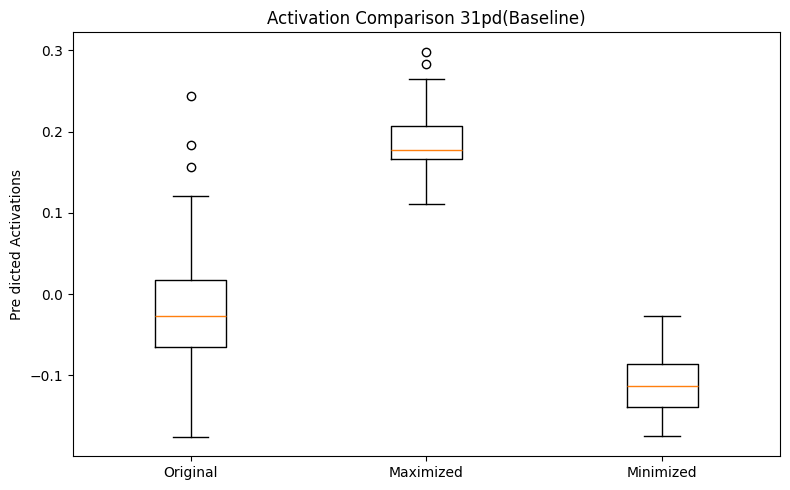

In [9]:
### Baseline method


# === CONFIG ===
unit_idx = 2
alpha = 1.0
gamma = 1.0
ROI = sub_1_lh_rois_unknown_ex[unit_idx]
img_dir = "../third_party/image_manipulation_code/outputs/1_" + ROI + "_" + str(alpha) + "_" + str(gamma) + "/img"
img_max_dir = "../third_party/image_manipulation_code/outputs/1_" + ROI + "_" + str(alpha) + "_" + str(gamma) + "/max"
img_min_dir = "../third_party/image_manipulation_code/outputs/1_" + ROI + "_" + str(alpha) + "_" + str(gamma) + "/min"
ckpt_path = ckpt_path_dino
unit_idx = unit_idx

# === Load encoder ===
encoder = EncoderModule.load_from_checkpoint(ckpt_path, strict=False).eval().to(device)

# === Transformation ===
transform_dino = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Lambda(lambda x: x if isinstance(x, torch.Tensor) else transforms.ToTensor()(x)),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# === Load and sort image paths ===
def load_images_from_dir(directory):
    paths = [os.path.join(directory, fname) for fname in os.listdir(directory) if fname.endswith('.png')]
    paths = sorted(paths, key=lambda f: int(os.path.splitext(os.path.basename(f))[0]))
    images = [Image.open(p).convert("RGB") for p in paths]
    return images

img_original = load_images_from_dir(img_dir)
img_max = load_images_from_dir(img_max_dir)
img_min = load_images_from_dir(img_min_dir)

# === Compute activations ===
def compute_dino_activation(images):
    tensor_batch = torch.stack([transform_dino(img) for img in images]).to(device)
    with torch.no_grad():
        feats = encoder(tensor_batch)
    return feats[:, unit_idx].cpu().numpy()

act_original = compute_dino_activation(img_original)
act_max = compute_dino_activation(img_max)
act_min = compute_dino_activation(img_min)

# === Plot boxplot (overall distribution) ===
plt.figure(figsize=(8, 5))
plt.boxplot([act_original, act_max, act_min], labels=["Original", "Maximized", "Minimized"])
plt.ylabel(f"Pre dicted Activations")
plt.title(f"Activation Comparison " + ROI + "(Baseline)")
plt.tight_layout()
plt.show()

Maximized (+1)


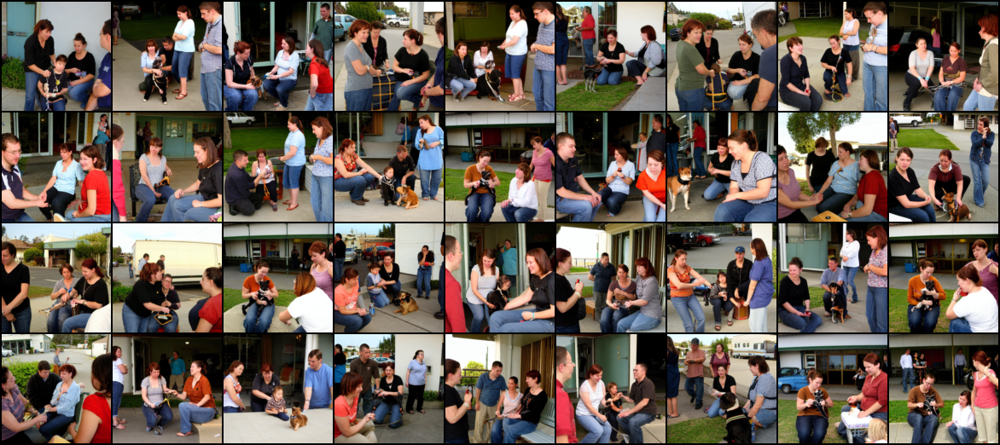

Minimized (-1)


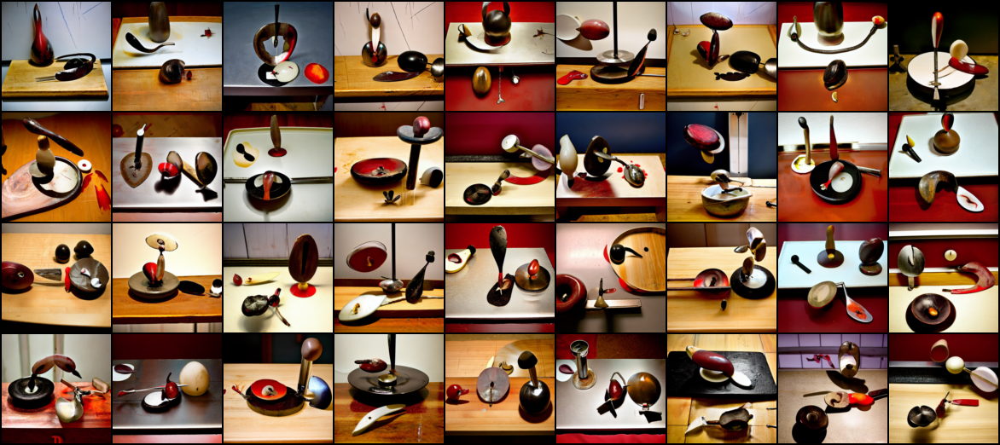

In [10]:
import torchvision.transforms as T
from IPython.display import display
from torchvision.utils import make_grid
resize_to = 128

transform_grid = transforms.Compose([
    transforms.Resize((resize_to, resize_to)),
    transforms.ToTensor()
])


def build_grid(images, resize_to=128, images_per_row=9):
    tensors = [transform_grid(img) for img in images[:36]]
    grid = make_grid(torch.stack(tensors), nrow=images_per_row, padding=2)
    return transforms.ToPILImage()(grid.clamp(0, 1))

# === Display all image batches as grids ===
"""
print("Original")
display(build_grid(img_original, resize_to=resize_to))
"""
print("Maximized (+1)")
display(build_grid(img_max, resize_to=resize_to))

print("Minimized (-1)")
display(build_grid(img_min, resize_to=resize_to))

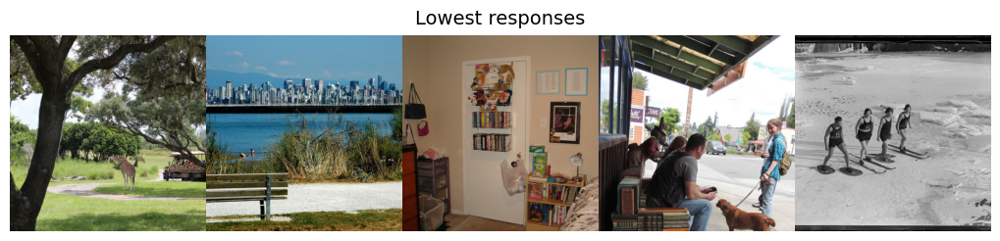

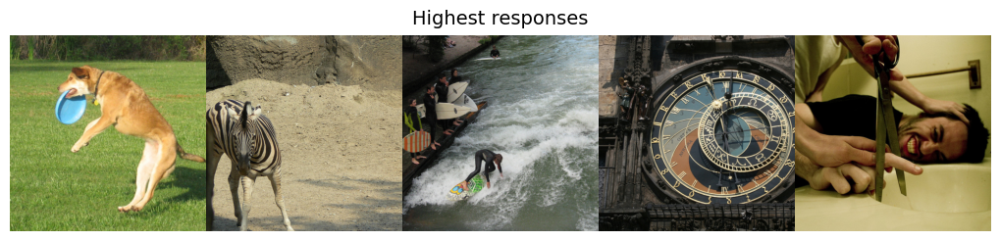

In [7]:
### Comapre with sorting the natural images in original dataset

%matplotlib inline
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
unit_idx = 2
# ── collect responses ───────────────────────────────────────────
losses = []
with torch.no_grad():
    for data, activation in trainloader:
        losses.append(activation[:, unit_idx])
losses_vis = torch.cat(losses)
sort_idx   = torch.argsort(losses_vis)                  # ascending

# ── load full batch of training images (only once) ──────────────
full_loader = torch.utils.data.DataLoader(trainset,
                                          batch_size=len(trainset),
                                          shuffle=False)
img_tensor, _ = next(iter(full_loader))                 # (N,3,H,W)

def show_row(indices, title=None):
    fig, ax = plt.subplots(1, 5,
                           figsize=(10, 3),
                           gridspec_kw=dict(wspace=0, hspace=0))
    for k, idx in enumerate(indices):
        ax[k].imshow(img_tensor[idx].permute(1, 2, 0))
        ax[k].axis("off")
    if title:
        fig.suptitle(title, y=0.92, fontsize=14)
    plt.subplots_adjust(left=0, right=1, top=1, bottom=0,
                        wspace=0, hspace=0)
    plt.show()

# ── 5 lowest responses ─────────────────────────────────────────
show_row(sort_idx[:5],   title="Lowest responses")

# ── 5 highest responses ────────────────────────────────────────
show_row(sort_idx[-5:],  title="Highest responses")

Using cache found in /common/home/yz1635/.cache/torch/hub/facebookresearch_dinov2_main


-0.029159546
0.10288398
Predicted activations  (unit 2)
Lowest‑5 : [-0.026 -0.088 -0.072  0.009  0.031]
Highest‑5: [0.039 0.031 0.109 0.178 0.157]


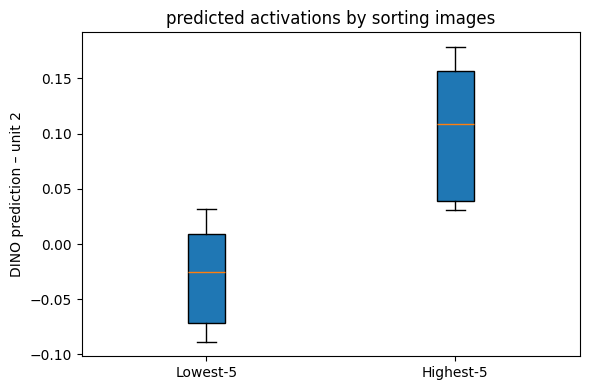

In [12]:
# ==============================================================
#  Predict DINO activations on lowest‑5 / highest‑5 images
# ==============================================================

import torch, numpy as np, matplotlib.pyplot as plt
from torchvision import transforms
from torchvision.transforms import ToPILImage
from methods.dino_encoder import EncoderModule

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

# ---------- config --------------------------------------------
CKPT_DINO  = "../checkpoints/dino_encoder-lh-unknown-8-ROI-ex-epoch=02-val_loss=0.11.ckpt"

# ---------- load DINO -----------------------------------------
encoder_dino = (
    EncoderModule
    .load_from_checkpoint(CKPT_DINO, strict=False)
    .eval()
    .to(device)
)

pre_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),
])

to_pil = ToPILImage()

@torch.no_grad()
def dino_pred(batch):                        # batch: (B,3,H,W) float, 0‑1
    pils  = [to_pil(t.cpu()) for t in batch]
    tens  = torch.stack([pre_tf(p) for p in pils]).to(device)
    feats = encoder_dino(tens)[:, unit_idx]  # (B,)
    return feats.cpu().numpy()

# ---------- select lowest‑5 / highest‑5 ------------------------
low5_idx  = sort_idx[:5]         # five smallest responses
high5_idx = sort_idx[-5:]        # five largest

low5_imgs  = img_tensor[low5_idx]           # (5,3,H,W)
high5_imgs = img_tensor[high5_idx]


low5_act  = dino_pred(low5_imgs)
high5_act = dino_pred(high5_imgs)
print(np.mean(low5_act))
print(np.mean(high5_act))

# ---------- results -------------------------------------------
print(f"Predicted activations  (unit {unit_idx})")
print("Lowest‑5 :", np.round(low5_act,  3))
print("Highest‑5:", np.round(high5_act, 3))

plt.figure(figsize=(6,4))
plt.boxplot([low5_act, high5_act],
            labels=["Lowest‑5","Highest‑5"],
            showfliers=True, patch_artist=True)
plt.ylabel(f"DINO prediction – unit {unit_idx}")
plt.title("predicted activations by sorting images")
plt.tight_layout()
plt.show()

## ANN Examples

In [3]:
# Import ANN modules(SimCLR)
sys.path.append("../")
import modules

# Load the main checkpoint
ckpt = torch.load('../checkpoints/resnet50_imagenet_bs2k_epochs600_linear.pth.tar')
ckpt['hparams'].encoder_ckpt = '../checkpoints/checkpoint-125100.pth.tar'
hparams = ckpt['hparams']


# Initialize the model
ANN_model = modules.ssl.SSLEval(hparams)
ANN_model.encoder.eval()
ANN_model.eval()

IMAGENET_PATH = /home/aashukha/imagenet/raw-data/
IMAGENET_PATH = /home/aashukha/imagenet/raw-data/
** Using avgpool **
======> Encoder: output dim 2048 | 25.557M parameters


In [4]:
from torch.utils.data import Dataset
import numpy as np
import os
from scipy import interpolate
from einops import rearrange
import json
import csv
import torch
from pathlib import Path
import torchvision.transforms as transforms

from torchvision import datasets
from torch.utils.data import Dataset, DataLoader

In [5]:
# Retrieve ANN unit activations(Trainset/Testset)
def test_input_for_unit_activation(net, layer_name, unit_idx, input_images):
    net.eval()
    target_activation = [None]

    def hook(module, input, output):
        if isinstance(unit_idx, tuple):
            
            activation = torch.mean(output, dim=(2, 3)) 
            target_activation[0] = activation
        else:
            target_activation[0] = output[:, unit_idx].mean(1).mean(1)

    # Register the hook to capture activations
    layers = {
        'layer1_0_conv1': net.encoder.model.convnet.layer1[0].conv1,
        'layer1_0_conv2': net.encoder.model.convnet.layer1[0].conv2,
        'layer2_2_conv2': net.encoder.model.convnet.layer2[2].conv2,
    }
    layer = layers[layer_name]
    hook_handle = layer.register_forward_hook(hook)
    with torch.no_grad():
        _ = net.encoder(input_images) 
    hook_handle.remove()  
    return target_activation[0]


device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
data_dir = '../datasets/imagenet-mini/train'
transform = transforms.Compose(
                [transforms.RandomResizedCrop(128, scale=(0.08, 1.0)),
                transforms.RandomHorizontalFlip(),
                transforms.ToTensor()]
                )
dataset = datasets.ImageFolder(root=data_dir, transform=transform)
data_loader = DataLoader(dataset, batch_size=100, shuffle=False, num_workers=4)
with torch.no_grad():
	train_feature_maps = []
	train_images = []
	for batch in data_loader:
		input_image = batch[0].to(device)
		activation_loss = test_input_for_unit_activation(
            ANN_model.to(device),
            layer_name='layer1_0_conv1',
            unit_idx=(5, 5),
            input_images=input_image
        )
        # Gather activations across all GPUs
		train_feature_maps.append(activation_loss.cpu())
		train_images.append(input_image.cpu())
	
	# Concatenate feature maps after gathering from all GPUs
	train_feature_maps_tensor = torch.cat(train_feature_maps, dim=0)
	train_images = torch.cat(train_images, dim=0)

print("All images:", train_images.shape)
print("Activation loss shape:", train_feature_maps_tensor.shape)
print("Max loss:", torch.max(train_feature_maps_tensor))
print("Min loss:", torch.min(train_feature_maps_tensor))

All images: torch.Size([34745, 3, 128, 128])
Activation loss shape: torch.Size([34745, 64])
Max loss: tensor(294.4456)
Min loss: tensor(-198.8978)


In [6]:
def test_input_for_unit_activation(net, layer_name, unit_idx, input_images):
    net.eval()
    target_activation = [None]

    def hook(module, input, output):
        if isinstance(unit_idx, tuple):
            
            activation = torch.mean(output, dim=(2, 3)) 
            target_activation[0] = activation
        else:
            target_activation[0] = output[:, unit_idx].mean(1).mean(1)

    # Register the hook to capture activations
    layers = {
        'layer1_0_conv1': net.encoder.model.convnet.layer1[0].conv1,
        'layer1_0_conv2': net.encoder.model.convnet.layer1[0].conv2,
        'layer2_2_conv2': net.encoder.model.convnet.layer2[2].conv2,
    }
    layer = layers[layer_name]
    hook_handle = layer.register_forward_hook(hook)
    with torch.no_grad():
        _ = net.encoder(input_images) 
    hook_handle.remove()  
    return target_activation[0]


device = torch.device('cuda:3' if torch.cuda.is_available() else 'cpu')
data_dir = '../datasets/imagenet-mini/val'
transform = transforms.Compose(
                [transforms.RandomResizedCrop(128, scale=(0.08, 1.0)),
                transforms.RandomHorizontalFlip(),
                transforms.ToTensor()]
                )
dataset = datasets.ImageFolder(root=data_dir, transform=transform)
data_loader = DataLoader(dataset, batch_size=100, shuffle=False, num_workers=4)
with torch.no_grad():
	test_feature_maps = []
	test_images = []
	for batch in data_loader:
		input_image = batch[0].to(device)
		activation_loss = test_input_for_unit_activation(
            ANN_model.to(device),
            layer_name='layer1_0_conv1',
            unit_idx=(5, 5),
            input_images=input_image
        )
        # Gather activations across all GPUs
		test_feature_maps.append(activation_loss.cpu())
		test_images.append(input_image.cpu())
	
	# Concatenate feature maps after gathering from all GPUs
	test_feature_maps_tensor = torch.cat(test_feature_maps, dim=0)
	test_images = torch.cat(test_images, dim=0)

print("All images:", test_images.shape)
print("Activation loss shape:", test_feature_maps_tensor.shape)
print("Max loss:", torch.max(test_feature_maps_tensor))
print("Min loss:", torch.min(test_feature_maps_tensor))

All images: torch.Size([3923, 3, 128, 128])
Activation loss shape: torch.Size([3923, 64])
Max loss: tensor(274.5108)
Min loss: tensor(-171.6983)


In [7]:
# Init CLIP Features of Imagenet datasets
import os, numpy as np, torch, torchvision as tv
from PIL import Image
from tqdm import tqdm
from transformers import CLIPProcessor, CLIPVisionModelWithProjection
from diffusers import StableDiffusionImg2ImgPipeline, DDIMScheduler

# ─────────────────── 1.  helper ────────────────────
proc224   = tv.transforms.Compose([
    tv.transforms.Resize(224, interpolation=Image.BICUBIC),
    tv.transforms.CenterCrop(224)
])
def ensure_pil_224(img):
    # path or (path,label) → PIL
    if isinstance(img, (tuple, list)) and isinstance(img[0], str):
        img = img[0]
    if isinstance(img, str):
        img = Image.open(img).convert("RGB")
    elif isinstance(img, torch.Tensor):
        if img.max() <= 1: img = (img*255).byte()
        img = tv.transforms.ToPILImage()(img.cpu())
    elif isinstance(img, np.ndarray):
        if img.dtype != np.uint8: img = (img*255).clip(0,255).astype(np.uint8)
        if img.ndim==3 and img.shape[0] in {1,3}: img = img.transpose(1,2,0)
        img = Image.fromarray(img)
    return proc224(img)

# ─────────────────── 2.  CLIP extractor ────────────
class CLIPExtractor(torch.nn.Module):
    def __init__(self, dev=device):
        super().__init__()
        self.dev = dev
        self.clip = CLIPVisionModelWithProjection.from_pretrained(
            "laion/CLIP-ViT-H-14-laion2B-s32B-b79K"
        ).to(dev)
        self.proc = CLIPProcessor.from_pretrained(
            "laion/CLIP-ViT-H-14-laion2B-s32B-b79K"
        )
    @torch.no_grad()
    def forward(self, pil_batch):          # list of PIL (len≤batch)
        pixel = self.proc(images=pil_batch, return_tensors="pt").pixel_values
        return self.clip(pixel.to(self.dev, dtype=torch.float16)).image_embeds

def extract_clip(img_paths, save_path):
    if os.path.exists(save_path):
        feats = np.load(save_path)
        
        if feats.shape[0] == len(img_paths): 
            return feats
    model = CLIPExtractor()
    feats = []
    for i in tqdm(range(0, len(img_paths), 64)):
        batch = [ensure_pil_224(p) for p in img_paths[i:i+64]]
        feats.append(model(batch).float().cpu())
    feats = torch.cat(feats).numpy()
    np.save(save_path, feats)
    return feats


# ─────────────────── 3.  load ImageNet subset ──────
from torchvision.datasets import ImageFolder
root = "../datasets/imagenet-mini/train"
ds   = ImageFolder(root)
img_paths = [p for p,_ in ds.imgs]

feat_path = "../datasets/imagenet-mini/train_features/clip_feats.npy"
clip_feats_train = extract_clip(img_paths, feat_path)




class CustomDatasetWithCLIP(Dataset):
    def __init__(self, images, clip_features, activations, transform=None):
        self.data = images
        self.activations = activations
        self.clip_features = clip_features
        self.transform = transform
    
    def __len__(self):
        return len(self.data)
    
    def __getitem__(self, idx):
        image = self.data[idx]
        activation_score = self.activations[idx]
        clip_feature = self.clip_features[idx]

        if isinstance(image, torch.Tensor):
            image = image.permute(1, 2, 0).numpy()
        elif image.ndim == 3 and image.shape[0] in {1, 3}:
            image = image.transpose(1, 2, 0)

        if self.transform:
            image = self.transform(image)
        return image, clip_feature, activation_score




transform = transforms.Compose([
    transforms.ToTensor(),  # Converts to (C, H, W) and scales to [0.0, 1.0]
])


# Initialize dataset and loader
trainset = CustomDatasetWithCLIP(train_images, clip_feats_train, train_feature_maps_tensor, transform=transform)
trainloader = DataLoader(trainset, batch_size=64, shuffle=False, num_workers=2)

In [8]:
import os, numpy as np, torch, torchvision as tv
from PIL import Image
from tqdm import tqdm
from transformers import CLIPProcessor, CLIPVisionModelWithProjection
from diffusers import StableDiffusionImg2ImgPipeline, DDIMScheduler

# ─────────────────── 1.  helper ────────────────────
proc224   = tv.transforms.Compose([
    tv.transforms.Resize(224, interpolation=Image.BICUBIC),
    tv.transforms.CenterCrop(224)
])
def ensure_pil_224(img):
    # path or (path,label) → PIL
    if isinstance(img, (tuple, list)) and isinstance(img[0], str):
        img = img[0]
    if isinstance(img, str):
        img = Image.open(img).convert("RGB")
    elif isinstance(img, torch.Tensor):
        if img.max() <= 1: img = (img*255).byte()
        img = tv.transforms.ToPILImage()(img.cpu())
    elif isinstance(img, np.ndarray):
        if img.dtype != np.uint8: img = (img*255).clip(0,255).astype(np.uint8)
        if img.ndim==3 and img.shape[0] in {1,3}: img = img.transpose(1,2,0)
        img = Image.fromarray(img)
    return proc224(img)

# ─────────────────── 2.  CLIP extractor ────────────
class CLIPExtractor(torch.nn.Module):
    def __init__(self, dev=device):
        super().__init__()
        self.dev = dev
        self.clip = CLIPVisionModelWithProjection.from_pretrained(
            "laion/CLIP-ViT-H-14-laion2B-s32B-b79K"
        ).to(dev)
        self.proc = CLIPProcessor.from_pretrained(
            "laion/CLIP-ViT-H-14-laion2B-s32B-b79K"
        )
    @torch.no_grad()
    def forward(self, pil_batch):          # list of PIL (len≤batch)
        pixel = self.proc(images=pil_batch, return_tensors="pt").pixel_values
        return self.clip(pixel.to(self.dev, dtype=torch.float16)).image_embeds

def extract_clip(img_paths, save_path):
    if os.path.exists(save_path):
        feats = np.load(save_path)
        
        if feats.shape[0] == len(img_paths): 
            return feats
    model = CLIPExtractor()
    feats = []
    for i in tqdm(range(0, len(img_paths), 64)):
        batch = [ensure_pil_224(p) for p in img_paths[i:i+64]]
        feats.append(model(batch).float().cpu())
    feats = torch.cat(feats).numpy()
    np.save(save_path, feats)
    return feats


# ─────────────────── 3.  load ImageNet subset ──────
from torchvision.datasets import ImageFolder
root = "../datasets/imagenet-mini/val"
ds   = ImageFolder(root)
img_paths = [p for p,_ in ds.imgs]

feat_path = "../datasets/imagenet-mini/test_features/clip_feats.npy"
clip_feats_test = extract_clip(img_paths, feat_path)




class CustomDatasetWithCLIP(Dataset):
    def __init__(self, images, clip_features, activations, transform=None):
        self.data = images
        self.activations = activations
        self.clip_features = clip_features
        self.transform = transform
    
    def __len__(self):
        return len(self.data)
    
    def __getitem__(self, idx):
        image = self.data[idx]
        activation_score = self.activations[idx]
        clip_feature = self.clip_features[idx]

        if isinstance(image, torch.Tensor):
            image = image.permute(1, 2, 0).numpy()
        elif image.ndim == 3 and image.shape[0] in {1, 3}:
            image = image.transpose(1, 2, 0)

        if self.transform:
            image = self.transform(image)
        return image, clip_feature, activation_score




transform = transforms.Compose([
    transforms.ToTensor(),  # Converts to (C, H, W) and scales to [0.0, 1.0]
])


# Initialize dataset and loader
testset = CustomDatasetWithCLIP(test_images, clip_feats_test, test_feature_maps_tensor, transform=transform)
testloader = DataLoader(testset, batch_size=64, shuffle=False, num_workers=2)

In [26]:
### Visualize CLIP Features' Space vs Organized VAE latent space on ANN unit Activations
from scipy.interpolate import griddata
def to_np(tensor_input):
    return tensor_input.detach().cpu().numpy()

def visualize_loss_landscape_unit(unit_idx, principal_components, loader):
    losses = []
    with torch.no_grad():
        for (_, _, loss) in loader:
            #data = data.to(device)
            losses.append(loss[:, unit_idx])
    
    losses_vis = torch.concat(losses)
    sort_indexes = np.argsort(to_np(losses_vis))

    # Sample data:
    x = to_np(principal_components[:, 0])
    y = to_np(principal_components[:, 1])
    z = to_np(losses_vis)
    


    # Create a grid in the range (-2, 2)
    xi = np.linspace(-2, 2, 100)
    yi = np.linspace(-2, 2, 100)
    Xi, Yi = np.meshgrid(xi, yi)

    # Interpolate z values onto this grid
    Zi = griddata((x, y), z, (Xi, Yi), method='linear')

    # 3D surface plot
    fig = plt.figure(figsize=(15, 12))
    ax = fig.add_subplot(111, projection='3d')
    surf = ax.plot_surface(Xi, Yi, Zi, cmap='jet')
    cbar = fig.colorbar(surf)
    cbar.ax.set_yticklabels([])
    #ax.set_xlabel('test MouseNet Latent 1')
    #ax.set_ylabel('test MouseNet Latent 2')
    #ax.set_zlabel('unit activation loss')
    #ax.set_title('unit activation loss over test images')
    ax.set_xlim(-2, 2)
    ax.set_ylim(-2, 2)
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_zticklabels([])
    #cbar = fig.colorbar(surf)
    ax.scatter(x, y, z, color='black', s=0.01)
    ax.view_init(elev=37, azim=270)
    plt.show()

    # 2D contour plot
    plt.figure(figsize=(8, 6))
    cp = plt.contourf(Xi, Yi, Zi, cmap='jet', levels=50)
    plt.colorbar(cp)
    plt.xlabel('Dim 1')
    plt.ylabel('Dim 2')
    plt.xlim(-2, 2)
    plt.ylim(-2, 2)
    plt.title('Unit Activations over test images')
    plt.scatter(x, y, color='black', s=0.05)
    plt.show()

In [10]:
CLIP_features = torch.from_numpy(clip_feats_test)

In [21]:
# Load VAE trained on CLIP features of imagenet and ANN unit activations
z_dim = 2048
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
CLIP_Transform_Encoder = CLIPtoCLIPVAE(latent_dim=z_dim, input_dim=1024).to(device)

state_dict = torch.load(
    '../checkpoints/ANN_LW_CLIPtoCLIP_VAE_layer1_0_conv1_unit_27_Constrain_zdim_2048_KLD_1_lamb_1.pt',
    map_location=device
)

# Load the state dict into your model
CLIP_Transform_Encoder.load_state_dict(state_dict)

<All keys matched successfully>

In [22]:
with torch.no_grad():
    CLIP_Transform_Encoder.eval()
    CLIP_Recon = CLIP_Transform_Encoder(CLIP_features.to(device))[0]
    Neuron_Code = CLIP_Transform_Encoder(CLIP_features.to(device))[1]

    mu, logvar = CLIP_Transform_Encoder.encode(CLIP_features.to(device)) 

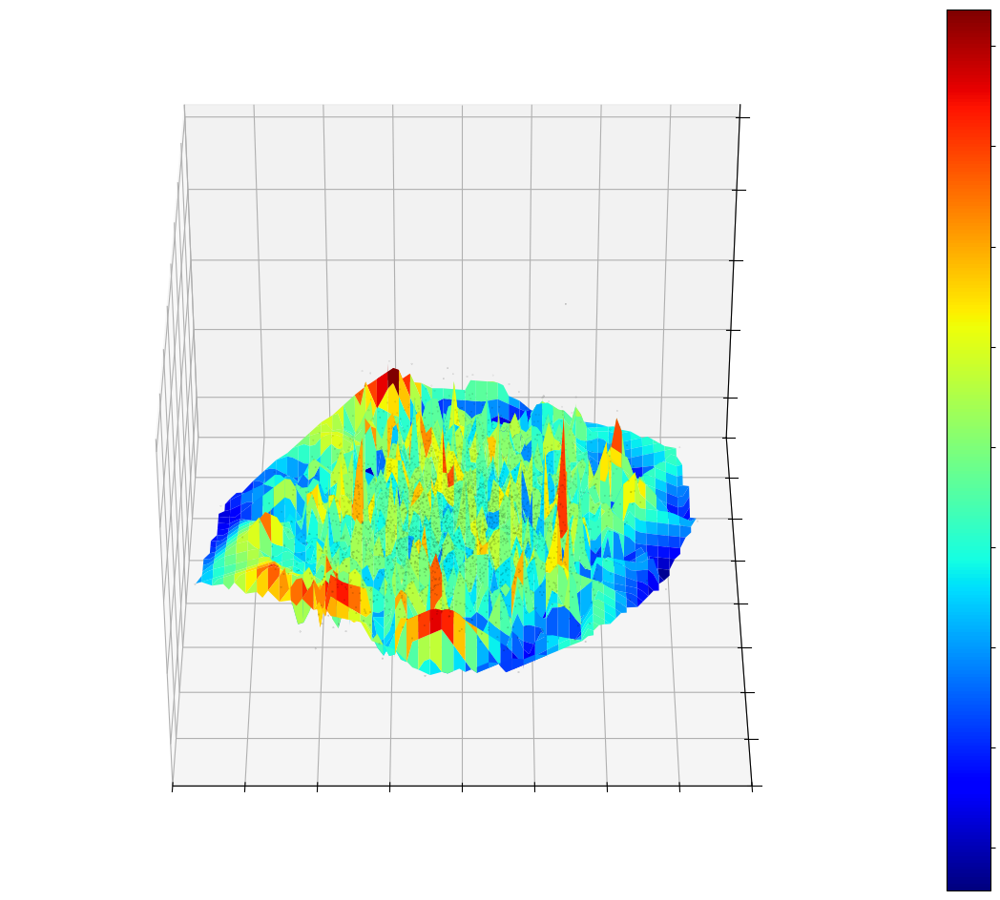

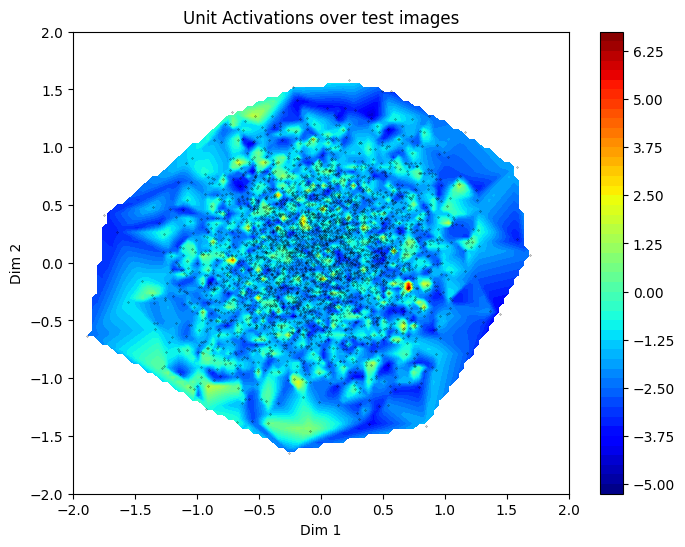

In [27]:
# Original CLIP
unit_idx = 27
visualize_loss_landscape_unit(unit_idx = unit_idx,
                              principal_components = CLIP_features[:,[0,1]],
                             loader = testloader)

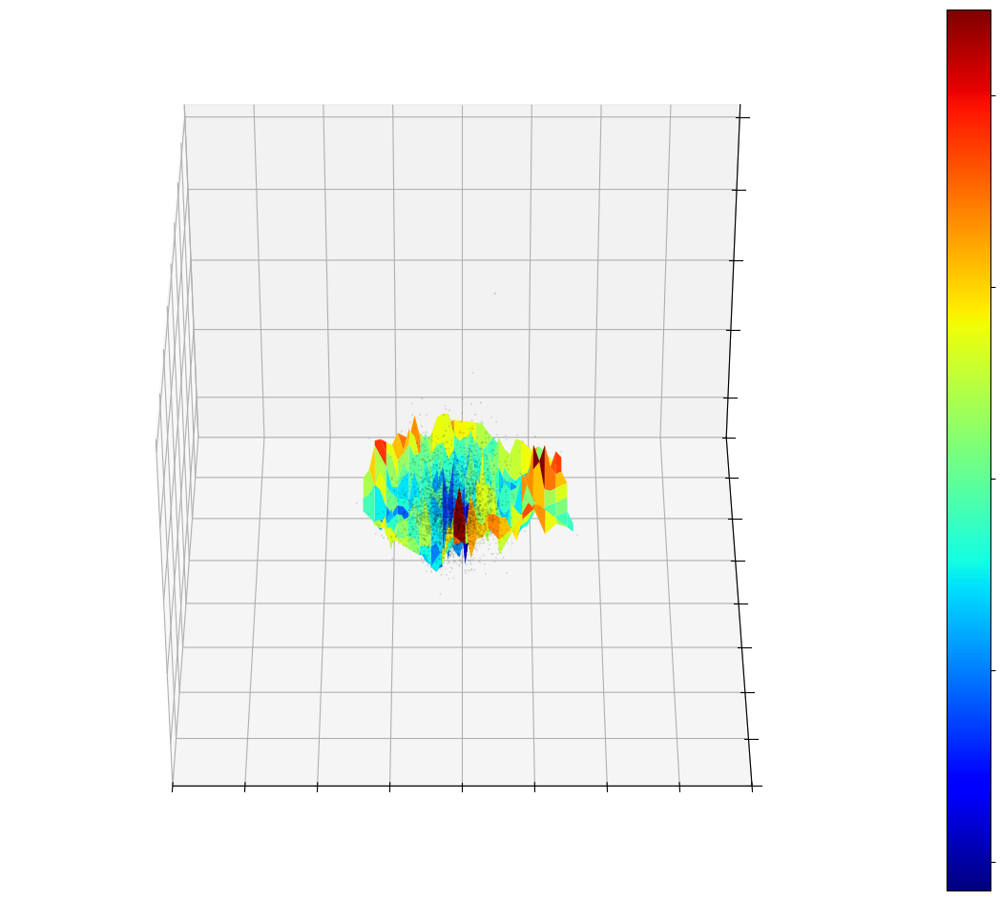

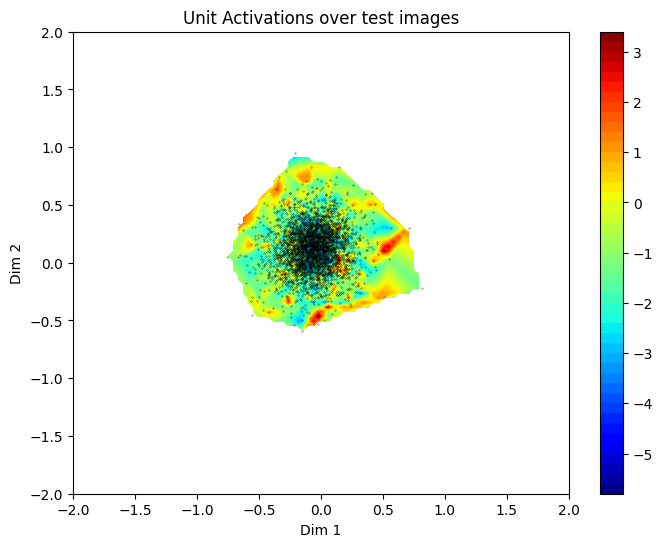

In [28]:
# Recon CLIP
visualize_loss_landscape_unit(unit_idx = unit_idx,
                              principal_components = CLIP_Recon[:,[0,1]],
                              loader = testloader)

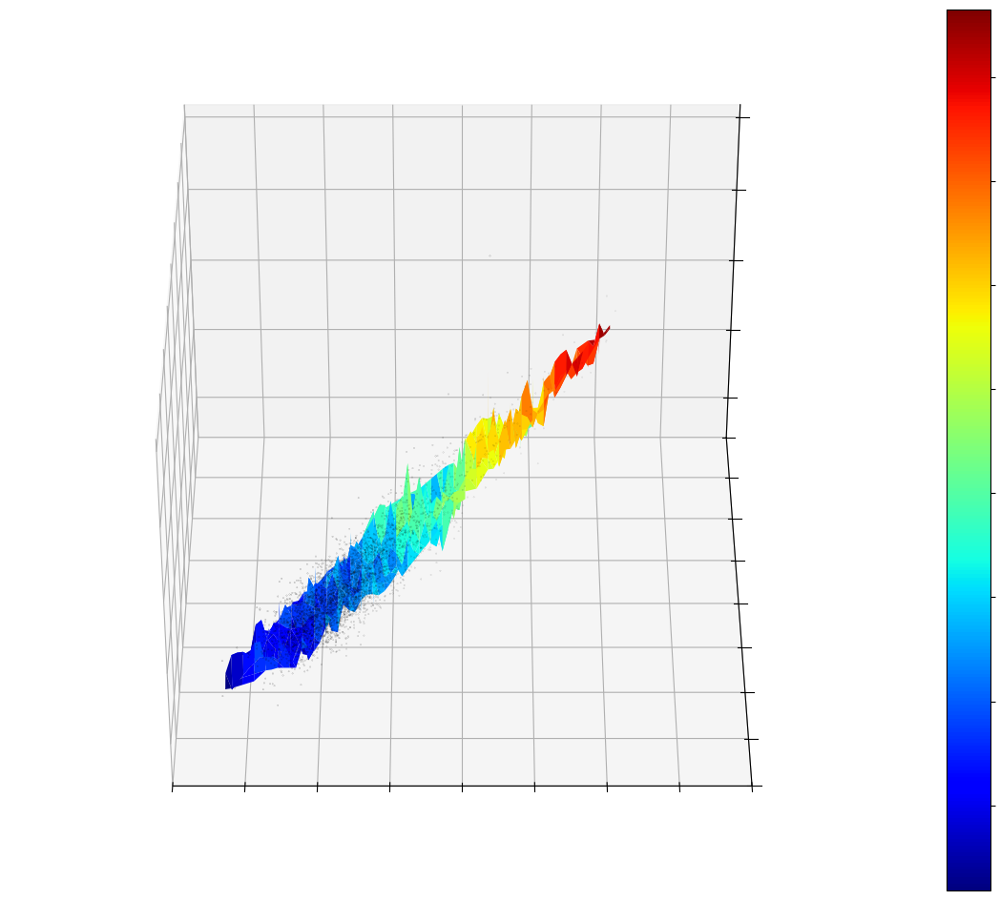

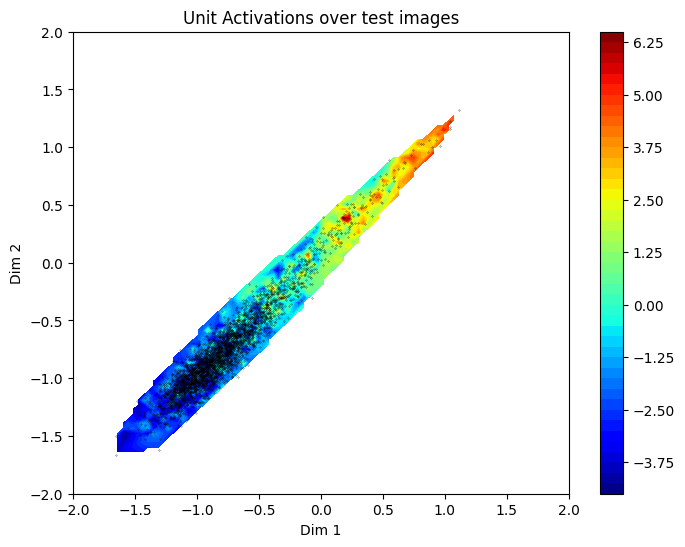

In [29]:
# Latent Space
visualize_loss_landscape_unit(unit_idx = unit_idx,
                              principal_components = mu[:,[0, 1]],
                             loader = testloader)

In [18]:
# load diffusion pipeline

diffusion_pipeline = StableDiffusionImg2ImgPipeline.from_pretrained("runwayml/stable-diffusion-v1-5", torch_dtype=torch.float16).to(device)
diffusion_pipeline.scheduler = DDIMScheduler.from_config(diffusion_pipeline.scheduler.config)
diffusion_pipeline.safety_checker = None
ip_model = IPAdapter(diffusion_pipeline, "laion/CLIP-ViT-H-14-laion2B-s32B-b79K", os.path.join("../third_party/image_manipulation_code/models", "ip-adapter_sd15.bin"), device)

Cannot initialize model with low cpu memory usage because `accelerate` was not found in the environment. Defaulting to `low_cpu_mem_usage=False`. It is strongly recommended to install `accelerate` for faster and less memory-intense model loading. You can do so with: 
```
pip install accelerate
```
.


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

### Visualize the generated preferred images of ANN Units of Our Method vs Baseline 

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

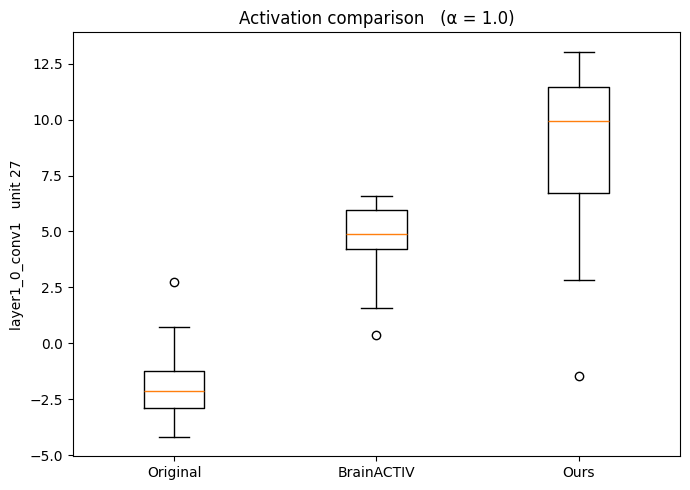

In [30]:
# ==============================================================
#        BrainACTIV   vs.   Our Structured‑VAE  (α = ALPHA)
# ==============================================================

def tslerp(val: float, low: torch.Tensor, high: torch.Tensor) -> torch.Tensor:
    """Torch‑based spherical interpolation (scalar α)."""
    low_n  = low  / low.norm(dim=-1, keepdim=True)
    high_n = high / high.norm(dim=-1, keepdim=True)
    omega  = torch.acos( (low_n*high_n).sum(-1, keepdim=True) )
    so     = torch.sin(omega).clamp_min(1e-9)
    return (torch.sin((1-val)*omega)/so)*low + (torch.sin(val*omega)/so)*high

import random, torch, numpy as np, matplotlib.pyplot as plt
from PIL import Image
import torchvision.utils as vutils
from torchvision.transforms import ToPILImage, Resize, Compose, ToTensor
from methods.slerp import slerp                               # <- your torch version

# -------------------------- hyper‑params -----------------------
ALPHA       = 1.0      # interpolation strength (same for both methods)
UNIT_IDX    = 27
LAYER_NAME  = "layer1_0_conv1"
KERNEL_IDX  = (5,5)
RIDGE_LAMB  = 10.0
N_TEST      = 32
GAMMA_SD    = 1.0
SEED        = 42
device      = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
# ---------------------------------------------------------------

# ---------------- reproducibility ------------------------------
random.seed(SEED);  np.random.seed(SEED);  torch.manual_seed(SEED)

to_pil     = ToPILImage()
resize_ip  = Resize((512,512),  interpolation=Image.BICUBIC)
resize_ann = Resize((128,128),  interpolation=Image.BICUBIC)
ann_tf     = Compose([resize_ann, ToTensor()])

# ##############################################################
# 1. modulation vector (BrainACTIV) on the TRAIN split
# ##############################################################
Xtr = torch.from_numpy(clip_feats_train).float()                  # (Ntr,1024)
Ytr = train_feature_maps_tensor[:, UNIT_IDX:UNIT_IDX+1].float()   # (Ntr,1)
Xn  = Xtr / Xtr.norm(dim=1, keepdim=True)
W   = torch.linalg.solve(Xn.T @ Xn + RIDGE_LAMB*torch.eye(1024), Xn.T @ Ytr)
# ---------- unit‑norm modulation vector ---------------------------
w_hat = W.squeeze(1)                    # (1024,)  torch
w_hat = w_hat / w_hat.norm()            # unit length

# -------------- project to CLIP feature sub‑space -----------------
w_hat_np = w_hat.cpu().numpy()          # → numpy 1‑D
w_hat_np = project_modulation_vector(clip_feats_train, w_hat_np)  # OK now

# ---------- back to torch & add batch‑dim -------------------------
w_hat = torch.from_numpy(w_hat_np).to(device)          # (1024,)
w_hat = w_hat / w_hat.norm()                           # safety
w_hat = w_hat.unsqueeze(0)                             # (1, 1024) — ready
# ##############################################################
# 2. common TEST mini‑batch  (same idx for all methods)
# ##############################################################
idx_sel      = np.random.choice(len(test_images), N_TEST, replace=False)
imgs_tensor  = test_images[idx_sel]                         # (B,3,H,W) float0‑1
clips_tensor = torch.from_numpy(clip_feats_test[idx_sel]).to(device)

pil_ref = [ resize_ip(to_pil((img*255).byte())) for img in imgs_tensor ]

# ##############################################################
# 3‑A.  BrainACTIV target embedding by slerp (α = ALPHA)
# ##############################################################
clip_bact = []
for e in clips_tensor:                                       # loop – needs numpy
    endp   = (w_hat * e.norm()).cpu().numpy()               # endpoint on the ray
    tgt    = tslerp(ALPHA, e.cpu(), torch.from_numpy(endp))  # torch‑based slerp
    clip_bact.append(tgt)
clip_bact = torch.stack(clip_bact).to(device)

# ##############################################################
# 3‑B.  Our Structured‑VAE target embedding (same α)
# ##############################################################
mu, logvar = CLIP_Transform_Encoder.encode(clips_tensor)
prior_pos  = torch.ones_like(mu)
mu_pos     = tslerp(ALPHA, mu, prior_pos)                    # spherical interp
clip_ours  = CLIP_Transform_Encoder.decode(mu_pos)

# ##############################################################
# 4.  IP‑Adapter generations (BrainACTIV & Ours)
# ##############################################################
def ip_generate(embeds):
    return ip_model.generate(clip_image_embeds   = embeds.half(),
                             image               = pil_ref,
                             strength            = GAMMA_SD,
                             num_samples         = 1,
                             num_inference_steps = 50,
                             seed                = SEED)

gen_bact = ip_generate(clip_bact)   # BrainACTIV
gen_ours = ip_generate(clip_ours)   # Our method

# ##############################################################
# 5.  ANN activations
# ##############################################################
def ann_activation(pils):
    batch = torch.stack([ann_tf(p).to(device) for p in pils])
    with torch.no_grad():
        v = test_input_for_unit_activation(
                ANN_model.to(device), LAYER_NAME, KERNEL_IDX, batch
            )[:, UNIT_IDX]
    return v.cpu().numpy()

act_orig = ann_activation(pil_ref)
act_bact = ann_activation(gen_bact)
act_ours = ann_activation(gen_ours)

# ##############################################################
# 6.  activation box‑plot
# ##############################################################
plt.figure(figsize=(7,5))
plt.boxplot([act_orig, act_bact, act_ours],
            labels=['Original','BrainACTIV','Ours'],
            showfliers=True)
plt.ylabel(f"{LAYER_NAME}   unit {UNIT_IDX}")
plt.title(f"Activation comparison   (α = {ALPHA})")
plt.tight_layout(); plt.show()


=== BRAINACTIV  (α={ALPHA}) ===


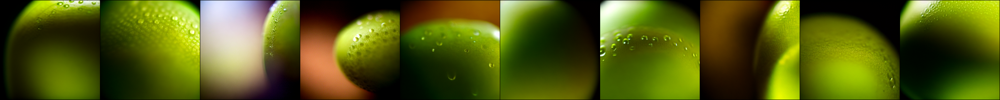


=== OUR METHOD  (α={ALPHA}) ===


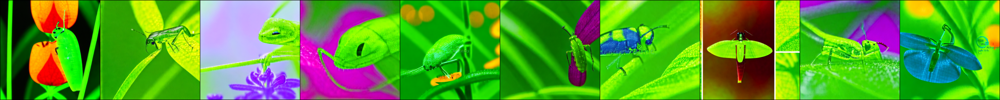

In [31]:
# ##############################################################
# 7.  visual grids  (each 4 × 8 = 32)
# ##############################################################
def make_grid(pils):                # list[PIL] → tensor grid
    return vutils.make_grid(torch.stack([ToTensor()(p) for p in pils]),
                            nrow=10, padding=2)

#grid_orig = make_grid(pil_ref[:10])
grid_bact = make_grid(gen_bact[:10])
grid_ours = make_grid(gen_ours[:10])

#print("\n=== ORIGINALS (4×8) ===");      display(to_pil(grid_orig))
print("\n=== BRAINACTIV  (α={ALPHA}) ==="); display(to_pil(grid_bact))
print("\n=== OUR METHOD  (α={ALPHA}) ===");  display(to_pil(grid_ours))

## Visualize Predictive Power of DINO Predictors

In [2]:
# Load Testset of NSD Dataset
import sys
sys.path.append('../modules')
sys.path.append('../third_party/image_manipulation_code')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from KLD_loss import loss_function

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import gc
import torch.nn.functional as F
from torch.optim.lr_scheduler import StepLR
from torch.utils.data import Dataset, DataLoader, random_split, TensorDataset
import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint

torch.manual_seed(42) 

import argparse
import os
from argparse import BooleanOptionalAction

import numpy as np
import torch
from PIL import Image
from diffusers import DDIMScheduler, StableDiffusionImg2ImgPipeline

from nsd_datasets.nsd import NaturalScenesDataset
from nsd_datasets.nsd_clip import CLIPExtractor, NSDCLIPFeaturesDataset
from IPA.ip_adapter import IPAdapter
from methods.slerp import slerp
from methods.projection import project_modulation_vector
from methods.dino_encoder import EncoderModule
from torchvision import transforms


subj1_lh_rois = ["aTL-faces", "EBA", "FBA-1", "FFA-1", "mfs-words", "OFA", "OPA", "OWFA"]
sub_1_lh_rois_unknown = ["IPS4", "SPL1", "TO1", "PHC2", "VO2", "PGi", "VVC", "TE2a"]
sub_1_lh_rois_unknown_ex = ["STSdp", "31a", "31pd", "DVT", "FST", "PGp", "PGs", "PH"]
sub_1_lh_rois_unknown_ex_2 = ["TE2p", "PHT", "TPOJ1", "TPOJ2", "TPOJ3", "IP0", "IP1", "IP2"]
sub_1_lh_rois_explored = ["OFA", "FFA-1", "EBA", "VWFA-1", "OPA", "PPA", "RSC", "OWFA"]
sub_1_lh_rois_mix = ["V1", "V2", "V3", "V4", "V8", "LO1", "LO2", "V4t"]

transform_dino = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Lambda(lambda x: x if isinstance(x, torch.Tensor) else transforms.ToTensor()(x)),  # ✅ Handles both cases
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

testset = NaturalScenesDataset(
                    root="../datasets/NSD_ex_1",
                    subject=1,
                    partition='test',
                    hemisphere='lh',
                    transform = transform_dino,
                    roi=sub_1_lh_rois_unknown_ex,
                    return_average=True,
                    tval_threshold=5
)

# Create test DataLoader
test_loader = DataLoader(testset, batch_size=64, shuffle=False)

[INFO] No tval file found for ROI 'STSdp' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI '31a' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI '31pd' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI 'DVT' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI 'FST' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI 'PGp' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI 'PGs' in lh, skipping tval thresholding.
[INFO] No tval file found for ROI 'PH' in lh, skipping tval thresholding.


In [3]:
# Import necessary libraries
import torch
from pytorch_lightning import Trainer
from torchvision import transforms

# Load the trained model from checkpoint
ckpt_path = "../checkpoints/dino_encoder-lh-unknown-8-ROI-ex-epoch=02-val_loss=0.11.ckpt" 
encoder = EncoderModule.load_from_checkpoint(ckpt_path, strict=False)
encoder.eval()  
encoder.to("cuda")  

Using cache found in /common/home/yz1635/.cache/torch/hub/facebookresearch_dinov2_main


EncoderModule(
  (backbone): DINO_Backbone(
    (backbone): DinoVisionTransformer(
      (patch_embed): PatchEmbed(
        (proj): Conv2d(3, 768, kernel_size=(14, 14), stride=(14, 14))
        (norm): Identity()
      )
      (blocks): ModuleList(
        (0-11): 12 x NestedTensorBlock(
          (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (attn): MemEffAttention(
            (qkv): Linear(in_features=768, out_features=2304, bias=True)
            (attn_drop): Dropout(p=0.0, inplace=False)
            (proj): Linear(in_features=768, out_features=768, bias=True)
            (proj_drop): Dropout(p=0.0, inplace=False)
          )
          (ls1): LayerScale()
          (drop_path1): Identity()
          (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
          (mlp): Mlp(
            (fc1): Linear(in_features=768, out_features=3072, bias=True)
            (act): GELU(approximate='none')
            (fc2): Linear(in_features=3072, out_features=7

In [4]:
# Evaluate the model on the test set
predictions = []
targets = []

with torch.no_grad():  # No gradient calculation needed
    for batch in test_loader:
        images, target = batch
        images = images.to("cuda")
        target = target.to("cuda")

        pred = encoder(images)  # Get model predictions
        predictions.append(pred.cpu())  # Move to CPU for easier processing
        targets.append(target.cpu())

# Convert lists to tensors
predictions = torch.cat(predictions, dim=0)
targets = torch.cat(targets, dim=0)

In [5]:
import torch.nn.functional as F

# Compute Mean Squared Error (MSE)
mse_loss = F.mse_loss(predictions, targets)
print(f"Test MSE Loss: {mse_loss.item():.4f}")

# Compute Pearson Correlation for each voxel/ROI
correlations = []
for i in range(targets.shape[1]):  # Loop over each ROI/voxel
    corr = torch.corrcoef(torch.stack([predictions[:, i], targets[:, i]]))[0, 1].item()
    correlations.append(corr)

# Print the average correlation
print(f"Average ROI/Voxel Correlation: {torch.tensor(correlations).mean().item():.4f}")

Test MSE Loss: 0.1073
Average ROI/Voxel Correlation: 0.3699


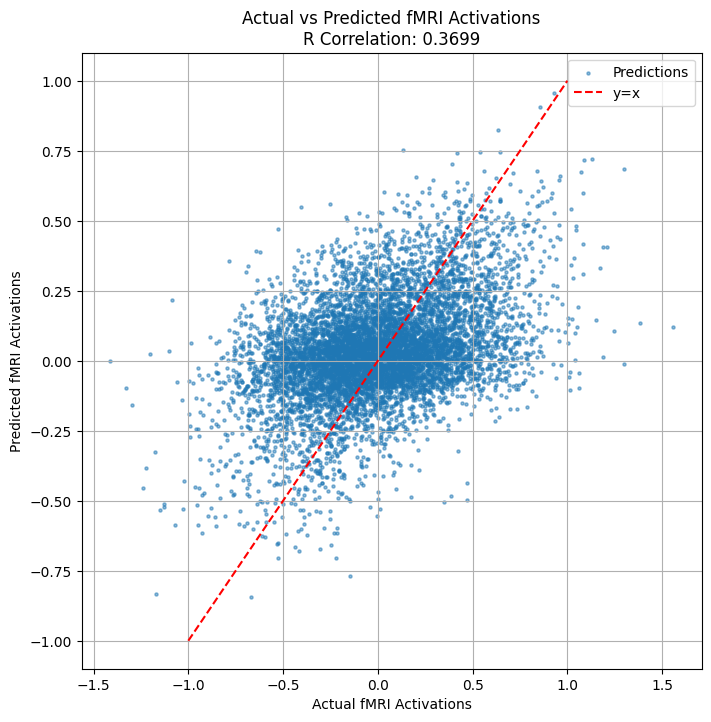

In [6]:
import matplotlib.pyplot as plt
import torch.nn.functional as F

# Convert predictions and targets to NumPy arrays for plotting
pred_np = predictions.numpy()
targets_np = targets.numpy()

# Compute Mean Squared Error (MSE)
mse_loss = F.mse_loss(predictions, targets).item()

# Plot actual vs predicted values
plt.figure(figsize=(8, 8))
plt.scatter(targets_np.flatten(), pred_np.flatten(), alpha=0.5, s=5, label="Predictions")
plt.plot([-1, 1], [-1, 1], 'r', linestyle='dashed', label="y=x")

plt.xlabel("Actual fMRI Activations")
plt.ylabel("Predicted fMRI Activations")
plt.title(f"Actual vs Predicted fMRI Activations\nR Correlation: {torch.tensor(correlations).mean().item():.4f}")
plt.legend()
plt.grid(True)
plt.show()